# Vibration-Based Motor Fault Diagnosis Using a 1-D CNN

## 1. Environment Setup

Import the libraries required for model training, evaluation, visualization, and saving experimental results.

In [1]:
from google.colab import drive
from pathlib import Path
import sys
import subprocess
import copy
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Mounted at /content/drive
Using device: cuda


### 1.1. Project Configuration

Define the dataset location and the directories used to store model checkpoints and experimental results.

The original experiments use vibration windows of 1024 samples.

In [2]:
PROJECT_DIR = DRIVE_ROOT / "ISCF_Project"
WINDOW_SIZE = 1024
DATA_PATH = PROJECT_DIR / "data" / f"hustmotor_{WINDOW_SIZE}.npz"
RESULTS_DIR = PROJECT_DIR / "results" / "CNN"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints" / "CNN"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

print("Dataset:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Checkpoints:", CHECKPOINT_DIR)

Dataset: /content/drive/MyDrive/ISCF_Project/data/hustmotor_1024.npz
Results: /content/drive/MyDrive/ISCF_Project/results/CNN
Checkpoints: /content/drive/MyDrive/ISCF_Project/checkpoints/CNN


### 1.2. Data Preparation Utilities

Import the preprocessing function and shared utilities for reproducibility, vibration dataset preparation, and DataLoader creation.

These functions are reused across the different vibration-based models.

In [3]:
# Shared utilities
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"

if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOKS_DIR))

from data_utils import (
    set_seed,
    make_loader,
    create_task_datasets
)

# Preprocessing repository
REPO_DIR = Path("/content/ISCF_Project")

if not (REPO_DIR / "preprocess_hustmotor.py").is_file():
    if REPO_DIR.exists():
        raise RuntimeError(
            "Repository directory exists, but the preprocessing script is missing."
        )

    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Genti24-bit/ISCF_Project.git",
            str(REPO_DIR)
        ],
        check=True
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from preprocess_hustmotor import load_dg_task

print("Shared utilities imported successfully!")
print("Preprocessing loader imported successfully!")

Vibration batch: torch.Size([32, 1, 1024])
Labels batch: torch.Size([32])
Labels dtype: torch.int64
Shared utilities imported successfully!
Preprocessing loader imported successfully!


## 2. Vibration Dataset Preparation

Prepare the training, validation, and test datasets for Task 9 using the predefined domain-generalization splits.

The 5 Hz operating condition is held out for testing, while the remaining operating speeds are used for training and validation. Vibration signals are converted into PyTorch datasets and organized into batches.

In [4]:
TASK_ID = 9
TARGET_DOMAIN = 0
BATCH_SIZE = 256

train_dataset, val_dataset, test_dataset = create_task_datasets(
    DATA_PATH,
    target_domain=TARGET_DOMAIN,
    load_dg_task=load_dg_task
)

train_loader = make_loader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = make_loader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = make_loader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Task {TASK_ID}")
print("Training:", train_dataset.tensors[0].shape)
print("Validation:", val_dataset.tensors[0].shape)
print("Testing:", test_dataset.tensors[0].shape)

xb, yb = next(iter(train_loader))

print("\nVibration batch:", xb.shape)
print("Labels batch:", yb.shape)

Task 9
Training: torch.Size([14400, 1, 1024])
Validation: torch.Size([3600, 1, 1024])
Testing: torch.Size([1200, 1, 1024])

Vibration batch: torch.Size([256, 1, 1024])
Labels batch: torch.Size([256])


## 3. 1-D CNN Architecture

Define a 1-D CNN with four convolutional blocks for extracting features from vibration signals.

Each block consists of convolution, batch normalization, ReLU activation, and max pooling. The extracted features are flattened and passed to a fully connected layer for classification into six motor conditions.

In [6]:
class VibrationCNN1D(nn.Module):

    def __init__(self, n_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=64),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=16),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 64, kernel_size=5),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )

        self.classifier = nn.Linear(3520, n_classes)

    def extract_features(self, x):
        return self.features(x).flatten(1)

    def forward(self, x):
        return self.classifier(self.extract_features(x))


model = VibrationCNN1D().to(device)

print(model)
print("\nTotal parameters:", sum(p.numel() for p in model.parameters()))

VibrationCNN1D(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(64,), stride=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(16,), stride=(1,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(5,), stride=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv1d(64, 64, kernel_size=(5,), stride=(1,))
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): MaxPool1d(kernel_size=2, stride=2, padding=0, dila

### 3.1. Architecture Verification

Verify that the CNN accepts 1024-point vibration windows and produces six classification scores, one for each motor condition.

In [18]:
model.eval()

dummy_input = torch.randn(8, 1, WINDOW_SIZE,device=device)

with torch.no_grad():
    features = model.extract_features(dummy_input)
    outputs = model(dummy_input)

print("Input:", dummy_input.shape)
print("Features:", features.shape)
print("Output:", outputs.shape)

assert features.shape == (8, 3520)
assert outputs.shape == (8, 6)

print("\nArchitecture verification passed!")

Input: torch.Size([8, 1, 1024])
Features: torch.Size([8, 3520])
Output: torch.Size([8, 6])

Architecture verification passed!


## 4. Training Configuration

Configure the CNN training procedure using the Adam optimizer, cross-entropy loss, and a decaying learning-rate schedule.

Each experiment runs for 50 epochs. Random seeds are controlled to support reproducibility and comparison across repeated experiments.

In [12]:
INITIAL_LR = 0.0005
EPOCHS = 50
SEED = 0

def learning_rate_schedule(epoch, total_epochs=EPOCHS):
    p = epoch / total_epochs
    return INITIAL_LR / ((1 + 10 * p) ** 0.75)

set_seed(SEED)

print("Initial learning rate:", learning_rate_schedule(0))
print("Final learning rate:", learning_rate_schedule(EPOCHS - 1))

Initial learning rate: 0.0005
Final learning rate: 8.392709437102133e-05


### 4.1. Model Evaluation

Define a reusable evaluation function to calculate classification loss and accuracy without updating the model parameters.

The function is used to evaluate validation performance during training and unseen-domain performance after checkpoint selection.

In [17]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

### 4.2. CNN Training Procedure

Define the training procedure using the Adam optimizer and cross-entropy loss.

At each epoch, record training and validation performance. Select the model checkpoint with the highest source-domain validation accuracy for final evaluation.

In [8]:
def train_model(train_loader, val_loader, seed=0, epochs=50, verbose=True):

    set_seed(seed)

    model = VibrationCNN1D().to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=INITIAL_LR
    )

    best_val_acc = -1.0
    best_epoch = 0
    best_weights = None
    history = []

    for epoch in range(epochs):

        lr = learning_rate_schedule(epoch, epochs)

        for group in optimizer.param_groups:
            group["lr"] = lr

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc = evaluate(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch + 1,
            "learning_rate": lr,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        if verbose:
            print(
                f"Epoch {epoch + 1:02d}/{epochs} | "
                f"Train Acc: {train_acc:.4f} | "
                f"Val Acc: {val_acc:.4f}"
            )

    model.load_state_dict(best_weights)

    return model, pd.DataFrame(history), best_epoch, best_val_acc

## 5. Single-Run Evaluation

Train the 1-D CNN for Task 9 using random seed 0, with the 5 Hz operating condition held out as the unseen target domain.

The model is trained for 50 epochs. At each epoch, training and validation loss and accuracy are reported to monitor convergence and generalization performance.

The checkpoint achieving the highest source-domain validation accuracy is selected for final evaluation on the unseen target domain.

In [13]:
TASK_ID = 9
SEED = 0

checkpoint_path = CHECKPOINT_DIR / "cnn_task9_seed0.pt"
history_path = RESULTS_DIR / "cnn_task9_seed0_history.csv"

if checkpoint_path.exists() and history_path.exists():

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model = VibrationCNN1D().to(device)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    history = pd.read_csv(history_path)

    best_epoch = int(checkpoint["best_epoch"])
    best_val_acc = float(checkpoint["best_val_accuracy"])

    print("Existing Task 9, seed 0 model loaded.\n")

    # Display previously saved epoch-by-epoch results
    for _, row in history.iterrows():

        print(
            f"Epoch {int(row['epoch']):02d}/{EPOCHS} | "
            f"Train Loss: {row['train_loss']:.4f} | "
            f"Train Acc: {row['train_accuracy']:.2%} | "
            f"Val Loss: {row['val_loss']:.4f} | "
            f"Val Acc: {row['val_accuracy']:.2%}"
        )

else:

    if checkpoint_path.exists() or history_path.exists():
        raise FileNotFoundError(
            "Only one of the checkpoint/history files exists. "
            "Check the saved files before continuing."
        )

    print("Training Task 9, seed 0...\n")

    set_seed(SEED)

    train_loader = make_loader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    model, history, best_epoch, best_val_acc = train_model(
        train_loader,
        val_loader,
        seed=SEED,
        epochs=EPOCHS,
        verbose=True
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "task": TASK_ID,
        "seed": SEED,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc
    }, checkpoint_path)

    history.to_csv(history_path, index=False)

print("\n" + "=" * 75)
print("TASK 9 — SEED 0 — TRAINING SUMMARY")
print("=" * 75)

print(f"Total epochs: {EPOCHS}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.2%}")

best_row = history.loc[
    history["epoch"] == best_epoch
].iloc[0]

print(f"Training accuracy at best epoch: {best_row['train_accuracy']:.2%}")
print(f"Training loss at best epoch: {best_row['train_loss']:.4f}")
print(f"Validation loss at best epoch: {best_row['val_loss']:.4f}")

Existing Task 9, seed 0 model loaded.

Epoch 01/50 | Train Loss: 0.5061 | Train Acc: 82.38% | Val Loss: 0.1363 | Val Acc: 95.28%
Epoch 02/50 | Train Loss: 0.0419 | Train Acc: 99.01% | Val Loss: 0.0516 | Val Acc: 98.14%
Epoch 03/50 | Train Loss: 0.0148 | Train Acc: 99.76% | Val Loss: 0.0141 | Val Acc: 99.72%
Epoch 04/50 | Train Loss: 0.0074 | Train Acc: 99.92% | Val Loss: 0.0165 | Val Acc: 99.61%
Epoch 05/50 | Train Loss: 0.0044 | Train Acc: 99.99% | Val Loss: 0.0094 | Val Acc: 99.67%
Epoch 06/50 | Train Loss: 0.0036 | Train Acc: 99.96% | Val Loss: 0.0126 | Val Acc: 99.67%
Epoch 07/50 | Train Loss: 0.0038 | Train Acc: 99.96% | Val Loss: 0.0041 | Val Acc: 99.92%
Epoch 08/50 | Train Loss: 0.0016 | Train Acc: 100.00% | Val Loss: 0.0026 | Val Acc: 99.94%
Epoch 09/50 | Train Loss: 0.0013 | Train Acc: 100.00% | Val Loss: 0.0024 | Val Acc: 99.92%
Epoch 10/50 | Train Loss: 0.0011 | Train Acc: 100.00% | Val Loss: 0.0026 | Val Acc: 99.92%
Epoch 11/50 | Train Loss: 0.0009 | Train Acc: 100.00% | Va

### 5.1. Learning Curves

Visualize training and validation accuracy and loss across epochs to examine convergence and potential overfitting.

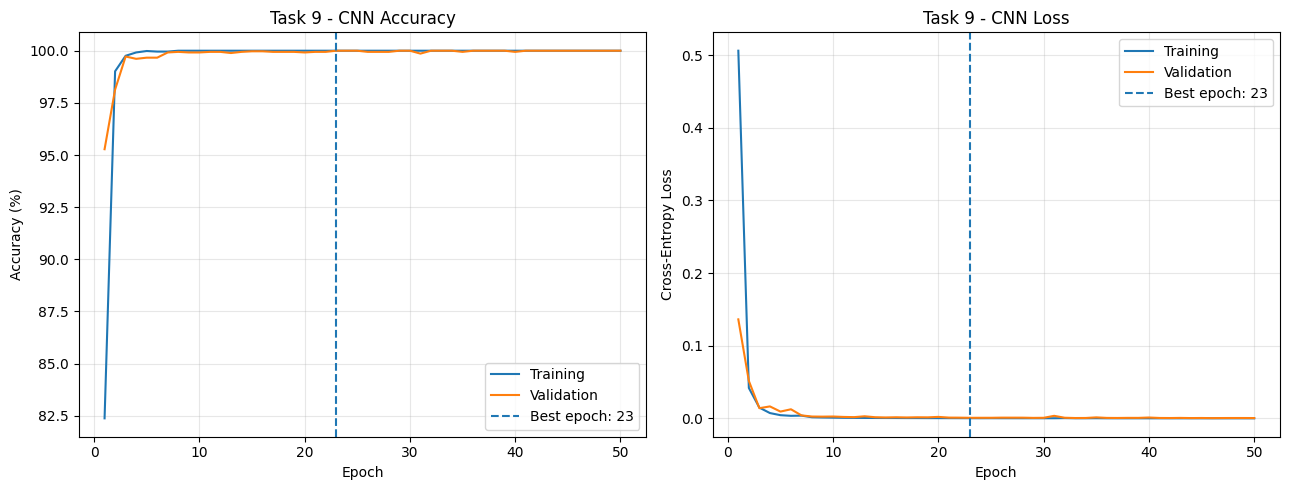

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history["epoch"],
    history["train_accuracy"] * 100,
    label="Training"
)

axes[0].plot(
    history["epoch"],
    history["val_accuracy"] * 100,
    label="Validation"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[0].set_title("Task 9 - CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history["epoch"],
    history["train_loss"],
    label="Training"
)

axes[1].plot(
    history["epoch"],
    history["val_loss"],
    label="Validation"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[1].set_title("Task 9 - CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2. Unseen-Domain Evaluation

Evaluate the selected CNN checkpoint on the unseen 5 Hz operating condition.

The target-domain test data is used only for final evaluation and is not involved in training or checkpoint selection.

In [19]:
criterion = nn.CrossEntropyLoss()

test_loss, test_acc = evaluate(model, test_loader, criterion)

print(f"Task: {TASK_ID}")
print(f"Seed: {SEED}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Test loss: {test_loss:.4f}")

Task: 9
Seed: 0
Best epoch: 23
Best validation accuracy: 100.00%
Test accuracy: 49.08%
Test loss: 3.5309


### 5.3. Fault Classification Performance

Generate a classification report and confusion matrix for the selected Task 9 model.

The report includes precision, recall, and F1-score for each motor condition, while the confusion matrix shows the distribution of correct predictions and misclassifications.

              precision    recall  f1-score   support

           H       0.93      1.00      0.97       200
          BF       0.79      0.76      0.77       200
         BOW       0.00      0.00      0.00       200
      BROKEN       0.67      0.01      0.02       200
       MISAL       1.00      0.34      0.51       200
       UNBAL       0.23      0.84      0.36       200

    accuracy                           0.49      1200
   macro avg       0.60      0.49      0.44      1200
weighted avg       0.60      0.49      0.44      1200



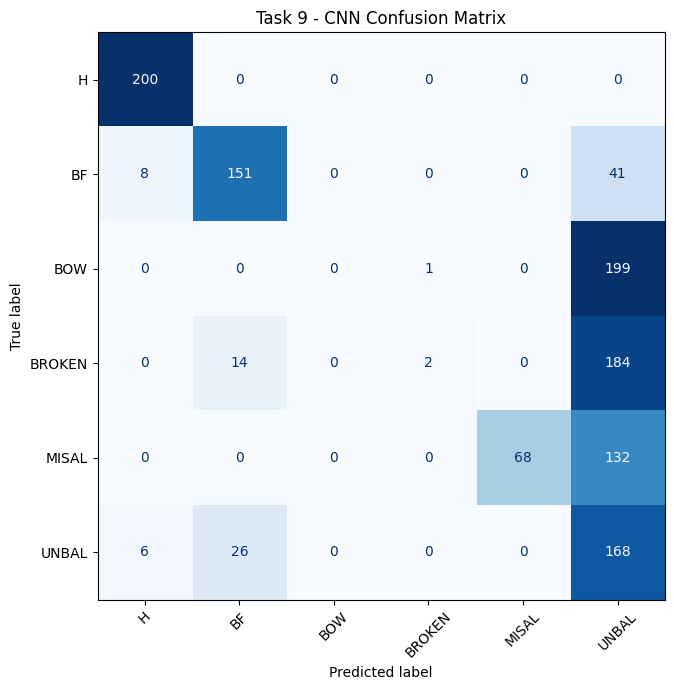

In [20]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        outputs = model(inputs.to(device))
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

with np.load(DATA_PATH, allow_pickle=False) as data:
    class_names = [str(c) for c in data["classes"]]

class_ids = list(range(len(class_names)))

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Task 9 - CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Full Experimental Evaluation

Evaluate the 1-D CNN across four domain-generalization tasks, corresponding to different unseen motor operating speeds.

Each task is repeated using 10 random seeds to assess performance variability.

For every task and seed, report the selected best epoch, training and validation accuracy and loss at that epoch, and final test accuracy and loss.

Aggregate the results to compare mean classification accuracy and standard deviation across unseen operating conditions.

In [21]:
TASKS = {
    9: 0,
    10: 1,
    11: 2,
    12: 3
}

SPEEDS = {
    9: 5,
    10: 10,
    11: 20,
    12: 30
}

SEEDS = range(10)

RUN_RESULTS_DIR = RESULTS_DIR / "full_experiments"
RUN_CHECKPOINT_DIR = CHECKPOINT_DIR / "full_experiments"

RUN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RUN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Number of tasks:", len(TASKS))
print("Seeds per task:", len(SEEDS))
print("Total experiments:", len(TASKS) * len(SEEDS))

Number of tasks: 4
Seeds per task: 10
Total experiments: 40


### 6.1. Existing Experiment Verification

Check whether the results from the 40 previously completed CNN experiments are available.

Existing results are preserved to avoid unnecessary retraining and accidental overwriting.

In [22]:
print("Saved CNN CSV files:\n")

csv_files = sorted(RESULTS_DIR.rglob("*.csv"))

for path in csv_files:
    print(path.relative_to(PROJECT_DIR))

print("\nSaved CNN checkpoints:\n")

checkpoint_files = sorted(
    CHECKPOINT_DIR.rglob("*.pt")
)

for path in checkpoint_files:
    print(path.relative_to(PROJECT_DIR))

print("\nCSV files found:", len(csv_files))
print("Checkpoints found:", len(checkpoint_files))

Saved CNN CSV files:

results/CNN/cnn_task9_seed0_history.csv

Saved CNN checkpoints:

checkpoints/CNN/cnn_task9_seed0.pt

CSV files found: 1
Checkpoints found: 1


### 6.2. CNN Training Across Tasks and Seeds

Train the CNN for each combination of domain-generalization task and random seed.

For each run, prepare the vibration datasets, initialize a new model, select the best checkpoint using source-domain validation accuracy, and evaluate it on the unseen target domain.

Save individual checkpoints, training histories, and evaluation results. Existing files are preserved.

In [24]:
# ============================================================
# 6.2. CNN Training Across Tasks and Seeds
# ============================================================

# Always create output directories
RUN_RESULTS_DIR = RESULTS_DIR / "full_experiments"
RUN_CHECKPOINT_DIR = CHECKPOINT_DIR / "full_experiments"

RUN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RUN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Four domain-generalization tasks
TASKS = {
    9: 0,
    10: 1,
    11: 2,
    12: 3
}

SPEEDS = {
    9: 5,
    10: 10,
    11: 20,
    12: 30
}

SEEDS = range(10)

all_results = []

for task_id, target_domain in TASKS.items():

    print("\n" + "=" * 90)
    print(
        f"TASK {task_id} | "
        f"Unseen operating speed: {SPEEDS[task_id]} Hz"
    )
    print("=" * 90)

    # Load data for the current task
    train_ds, val_ds, test_ds = create_task_datasets(
        DATA_PATH,
        target_domain=target_domain,
        load_dg_task=load_dg_task
    )

    val_dl = make_loader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_dl = make_loader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    task_results = []

    for seed in SEEDS:

        print(f"\n{'-' * 90}")
        print(f"TASK {task_id} — SEED {seed}")
        print(f"{'-' * 90}")

        # Reinitialize the random seed and training loader
        set_seed(seed)

        train_dl = make_loader(
            train_ds,
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        start_time = time.time()

        # Train a new CNN for this task and seed
        trained_model, history_df, best_epoch, best_val_acc = train_model(
            train_dl,
            val_dl,
            seed=seed,
            epochs=EPOCHS,
            verbose=False
        )

        # Evaluate on the unseen target domain
        test_loss, test_acc = evaluate(
            trained_model,
            test_dl,
            nn.CrossEntropyLoss()
        )

        training_time = time.time() - start_time

        # Retrieve training/validation metrics at best epoch
        best_row = history_df.loc[
            history_df["epoch"] == best_epoch
        ].iloc[0]

        train_loss = float(best_row["train_loss"])
        train_acc = float(best_row["train_accuracy"])

        val_loss = float(best_row["val_loss"])
        val_acc = float(best_row["val_accuracy"])

        # Store experimental results
        result = {
            "Task": task_id,
            "Speed (Hz)": SPEEDS[task_id],
            "Seed": seed,
            "Best Epoch": best_epoch,
            "Train Loss": train_loss,
            "Train Accuracy (%)": train_acc * 100,
            "Val Loss": val_loss,
            "Val Accuracy (%)": val_acc * 100,
            "Test Loss": test_loss,
            "Test Accuracy (%)": test_acc * 100,
            "Training Time (s)": training_time
        }

        task_results.append(result)
        all_results.append(result)

        # Print results for current run
        print(
            f"Best Epoch: {best_epoch} | "
            f"Train Acc: {train_acc:.2%} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Acc: {val_acc:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Test Acc: {test_acc:.2%} | "
            f"Test Loss: {test_loss:.4f}"
        )

        # Save model checkpoint
        checkpoint_path = (
            RUN_CHECKPOINT_DIR /
            f"cnn_task{task_id}_seed{seed}.pt"
        )

        torch.save({
            "model_state_dict": trained_model.state_dict(),
            "task": task_id,
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_acc,
            "test_accuracy": test_acc,
            "test_loss": test_loss
        }, checkpoint_path)

        # Save training history (all 50 epochs)
        history_path = (
            RUN_RESULTS_DIR /
            f"cnn_task{task_id}_seed{seed}_history.csv"
        )

        history_df.to_csv(history_path, index=False)

        # Save individual experiment result
        result_path = (
            RUN_RESULTS_DIR /
            f"cnn_task{task_id}_seed{seed}_result.csv"
        )

        pd.DataFrame([result]).to_csv(
            result_path,
            index=False
        )

        # Save combined progress after every seed
        pd.DataFrame(all_results).to_csv(
            RUN_RESULTS_DIR / "cnn_detailed_results.csv",
            index=False
        )

        # Release memory
        del trained_model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Display all 10 seeds for the current task
    task_df = pd.DataFrame(task_results)

    print("\n" + "=" * 90)
    print(f"TASK {task_id} — RESULTS FOR ALL 10 SEEDS")
    print("=" * 90)

    display(
        task_df.style.format({
            "Train Loss": "{:.4f}",
            "Train Accuracy (%)": "{:.2f}",
            "Val Loss": "{:.4f}",
            "Val Accuracy (%)": "{:.2f}",
            "Test Loss": "{:.4f}",
            "Test Accuracy (%)": "{:.2f}",
            "Training Time (s)": "{:.1f}"
        })
    )

    print(
        f"\nMean Test Accuracy: "
        f"{task_df['Test Accuracy (%)'].mean():.2f}%"
    )

    print(
        f"Standard Deviation: "
        f"{task_df['Test Accuracy (%)'].std(ddof=1):.2f}%"
    )

# Final detailed results
detailed_results_df = pd.DataFrame(all_results)

print("\n" + "=" * 90)
print("ALL 40 CNN EXPERIMENTS COMPLETED")
print("=" * 90)

print(f"Total runs: {len(detailed_results_df)}")

display(detailed_results_df)

print(
    "\nSaved results to:",
    RUN_RESULTS_DIR / "cnn_detailed_results.csv"
)


TASK 9 | Unseen operating speed: 5 Hz

------------------------------------------------------------------------------------------
TASK 9 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 23 | Train Acc: 100.00% | Train Loss: 0.0003 | Val Acc: 100.00% | Val Loss: 0.0008 | Test Acc: 49.08% | Test Loss: 3.5309

------------------------------------------------------------------------------------------
TASK 9 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 27 | Train Acc: 100.00% | Train Loss: 0.0003 | Val Acc: 100.00% | Val Loss: 0.0011 | Test Acc: 59.33% | Test Loss: 2.4722

------------------------------------------------------------------------------------------
TASK 9 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 13 | Train Acc: 100.00% | Train Loss: 0.0005 | Val Acc: 100.00% | Val Loss: 0.0012 |

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,9,5,0,23,0.0003,100.00,0.0008,100.00,3.5309,49.08,68.9
1,9,5,1,27,0.0003,100.00,0.0011,100.00,2.4722,59.33,61.8
2,9,5,2,13,0.0005,100.00,0.0012,100.00,2.1224,58.92,62.0
3,9,5,3,5,0.0033,99.97,0.0040,100.00,2.4590,49.83,61.7
4,9,5,4,18,0.0004,100.00,0.0019,99.97,2.5476,57.50,61.9
5,9,5,5,42,0.0001,100.00,0.0006,100.00,1.9399,62.58,62.2
6,9,5,6,21,0.0003,100.00,0.0014,99.97,3.2765,53.33,62.1
7,9,5,7,28,0.0002,100.00,0.0006,100.00,2.4560,56.00,62.9
8,9,5,8,13,0.0009,100.00,0.0032,99.97,2.1032,59.50,62.3
9,9,5,9,6,0.0046,99.97,0.0037,100.00,2.0700,62.42,62.3



Mean Test Accuracy: 56.85%
Standard Deviation: 4.77%

TASK 10 | Unseen operating speed: 10 Hz

------------------------------------------------------------------------------------------
TASK 10 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 46 | Train Acc: 100.00% | Train Loss: 0.0003 | Val Acc: 99.75% | Val Loss: 0.0100 | Test Acc: 98.33% | Test Loss: 0.0533

------------------------------------------------------------------------------------------
TASK 10 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 41 | Train Acc: 100.00% | Train Loss: 0.0004 | Val Acc: 99.56% | Val Loss: 0.0142 | Test Acc: 99.25% | Test Loss: 0.0237

------------------------------------------------------------------------------------------
TASK 10 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 40 | Train Acc: 100.00% | T

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,10,10,0,46,0.0003,100.00,0.0100,99.75,0.0533,98.33,62.4
1,10,10,1,41,0.0004,100.00,0.0142,99.56,0.0237,99.25,62.6
2,10,10,2,40,0.0005,100.00,0.0071,99.75,0.0302,99.08,62.7
3,10,10,3,24,0.0008,100.00,0.0063,99.86,0.0074,99.83,62.8
4,10,10,4,38,0.0005,100.00,0.0106,99.72,0.0162,99.25,62.5
5,10,10,5,34,0.0005,100.00,0.0083,99.78,0.0136,99.42,62.3
6,10,10,6,40,0.0003,100.00,0.0057,99.81,0.0096,99.58,62.4
7,10,10,7,33,0.0006,100.00,0.0076,99.86,0.0240,99.17,62.1
8,10,10,8,35,0.0005,100.00,0.0128,99.64,0.0234,99.17,62.0
9,10,10,9,47,0.0003,100.00,0.0059,99.86,0.0079,99.75,62.0



Mean Test Accuracy: 99.28%
Standard Deviation: 0.42%

TASK 11 | Unseen operating speed: 20 Hz

------------------------------------------------------------------------------------------
TASK 11 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 36 | Train Acc: 99.99% | Train Loss: 0.0007 | Val Acc: 99.86% | Val Loss: 0.0084 | Test Acc: 97.25% | Test Loss: 0.0853

------------------------------------------------------------------------------------------
TASK 11 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 37 | Train Acc: 100.00% | Train Loss: 0.0006 | Val Acc: 99.78% | Val Loss: 0.0107 | Test Acc: 92.50% | Test Loss: 0.3212

------------------------------------------------------------------------------------------
TASK 11 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 45 | Train Acc: 100.00% | Tr

...


Mean Test Accuracy: 93.92%
Standard Deviation: 2.10%

TASK 12 | Unseen operating speed: 30 Hz

------------------------------------------------------------------------------------------
TASK 12 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 42 | Train Acc: 100.00% | Train Loss: 0.0003 | Val Acc: 99.81% | Val Loss: 0.0063 | Test Acc: 83.33% | Test Loss: 1.2743

------------------------------------------------------------------------------------------
TASK 12 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 40 | Train Acc: 100.00% | Train Loss: 0.0004 | Val Acc: 99.86% | Val Loss: 0.0067 | Test Acc: 83.50% | Test Loss: 1.4249

------------------------------------------------------------------------------------------
TASK 12 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 36 | Train Acc: 100.00% | T

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,12,30,0,42,0.0003,100.00,0.0063,99.81,1.2743,83.33,61.8
1,12,30,1,40,0.0004,100.00,0.0067,99.86,1.4249,83.50,61.8
2,12,30,2,36,0.0004,100.00,0.0043,99.92,1.0803,83.25,61.9
3,12,30,3,46,0.0003,100.00,0.0040,99.92,1.5118,73.83,62.3
4,12,30,4,40,0.0004,100.00,0.0107,99.75,1.4568,83.33,61.7
5,12,30,5,30,0.0012,99.99,0.0079,99.83,1.7318,69.00,61.8
6,12,30,6,20,0.0010,100.00,0.0052,99.92,1.7153,72.67,61.8
7,12,30,7,21,0.0011,100.00,0.0067,99.94,1.7116,67.50,61.9
8,12,30,8,37,0.0004,100.00,0.0096,99.72,1.5649,83.33,61.9
9,12,30,9,47,0.0003,100.00,0.0052,99.86,1.1681,83.42,61.8



Mean Test Accuracy: 78.32%
Standard Deviation: 6.74%

ALL 40 CNN EXPERIMENTS COMPLETED
Total runs: 40


,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,9,5,0,23,0.000295,100.000000,0.000831,100.000000,3.530908,49.083333,68.888870
1,9,5,1,27,0.000333,100.000000,0.001064,100.000000,2.472173,59.333333,61.802486
2,9,5,2,13,0.000502,100.000000,0.001151,100.000000,2.122432,58.916667,61.985764
3,9,5,3,5,0.003293,99.972222,0.003980,100.000000,2.459032,49.833333,61.726005
4,9,5,4,18,0.000396,100.000000,0.001851,99.972222,2.547622,57.500000,61.929006
5,9,5,5,42,0.000138,100.000000,0.000627,100.000000,1.939887,62.583333,62.166834
6,9,5,6,21,0.000315,100.000000,0.001435,99.972222,3.276508,53.333333,62.060296
7,9,5,7,28,0.000225,100.000000,0.000618,100.000000,2.455976,56.000000,62.873373
8,9,5,8,13,0.000854,100.000000,0.003158,99.972222,2.103190,59.500000,62.335810
9,9,5,9,6,0.004598,99.965278,0.003720,100.000000,2.069991,62.416667,62.307223



Saved results to: /content/drive/MyDrive/ISCF_Project/results/CNN/full_experiments/cnn_detailed_results.csv


### 6.3. Experimental Results Summary

Verify that all 40 task-seed combinations are represented and calculate the mean and standard deviation of unseen-domain test accuracy for each task.

The resulting summary is used to compare CNN performance across different operating conditions.

In [26]:
results_path = RUN_RESULTS_DIR / "cnn_detailed_results.csv"

if results_path.exists():
    results_df = pd.read_csv(results_path)
else:
    raise FileNotFoundError(
        "No experiment results found. Run Section 6.2 first."
    )

required_columns = {
    "Task",
    "Speed (Hz)",
    "Seed",
    "Best Epoch",
    "Test Loss",
    "Test Accuracy (%)"
}

assert required_columns.issubset(results_df.columns), (
    f"Missing columns: {required_columns - set(results_df.columns)}"
)

expected_runs = {
    (task_id, seed)
    for task_id in TASKS
    for seed in SEEDS
}

actual_runs = {
    (int(row["Task"]), int(row["Seed"]))
    for _, row in results_df.iterrows()
}

assert len(results_df) == 40, "Expected 40 results."

assert actual_runs == expected_runs, (
    "Missing or unexpected task-seed combinations."
)

# Calculate summary statistics for each task
summary_df = (
    results_df
    .groupby(["Task", "Speed (Hz)"])
    .agg(
        Mean_Test_Accuracy=("Test Accuracy (%)", "mean"),
        Std_Test_Accuracy=("Test Accuracy (%)", "std"),
        Mean_Test_Loss=("Test Loss", "mean"),
        Mean_Best_Epoch=("Best Epoch", "mean"),
        Number_of_Seeds=("Seed", "count")
    )
    .reset_index()
)

# Display summary
display(
    summary_df.style.format({
        "Mean_Test_Accuracy": "{:.2f}",
        "Std_Test_Accuracy": "{:.2f}",
        "Mean_Test_Loss": "{:.4f}",
        "Mean_Best_Epoch": "{:.1f}"
    })
)

# Overall mean accuracy across all four tasks
overall_accuracy = summary_df["Mean_Test_Accuracy"].mean()

print(f"\nOverall Mean Test Accuracy: {overall_accuracy:.2f}%")

# Save summary
summary_df.to_csv(RUN_RESULTS_DIR / "cnn_summary.csv",index=False)

print("\nSummary saved successfully!")

,Task,Speed (Hz),Mean_Test_Accuracy,Std_Test_Accuracy,Mean_Test_Loss,Mean_Best_Epoch,Number_of_Seeds
0,9,5,56.85,4.77,2.4978,19.6,10
1,10,10,99.28,0.42,0.0209,37.8,10
2,11,20,93.92,2.10,0.2589,36.4,10
3,12,30,78.32,6.74,1.4640,35.9,10



Overall Mean Test Accuracy: 82.09%

Summary saved successfully!


### 6.4. Performance Across Unseen Operating Speeds

Visualize the mean CNN classification accuracy for each domain-generalization task.

Error bars represent the standard deviation across 10 random seeds, illustrating the variability of model performance under different unseen operating conditions.

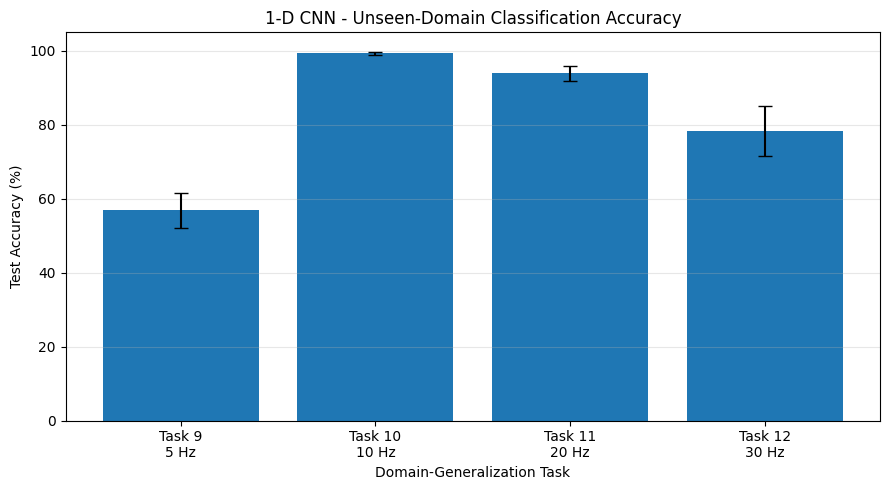

In [27]:
task_labels = [
    f"Task {int(row['Task'])}\n{int(row['Speed (Hz)'])} Hz"
    for _, row in summary_df.iterrows()
]

plt.figure(figsize=(9, 5))

plt.bar(
    task_labels,
    summary_df["Mean_Test_Accuracy"],
    yerr=summary_df["Std_Test_Accuracy"],
    capsize=5
)

plt.title("1-D CNN - Unseen-Domain Classification Accuracy")
plt.xlabel("Domain-Generalization Task")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()